### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4-overexpression metabolomics (ReSOLUTE, HEK293)

Single analysis notebook for all three metabolomics panels — all three draw on the same ReSOLUTE
targeted metabolomics dataset (HEK293 cells stably overexpressing SLC38A4 vs control, 186 metabolites)
and the same MetaboAnalyst pathway enrichment run, so they're grouped here rather than split across
separate notebooks.

**Outputs**
- **Fig 3G** — compact bar chart: log2FC of the 14 System A substrates, 4 urea-cycle intermediates and 3 carbamoyl-phosphate pathway markers
  (main figure).
- **Fig S9A** — full 186-metabolite volcano plot, same substrate/urea-cycle/oxidative-stress groups,
  full thematic colour-coding.
- **Fig S9B** — MetaboAnalyst pathway enrichment of the significantly altered metabolites (16 pathways,
  FDR < 0.05), colour-coded by theme.

**Data**: `Fig3G_metabolomics_data.csv` (curated substrate/urea-cycle subset, 21 rows, used by Fig 3G);
`ReSOLUTE_metabolomics_SLC48A4OE.xlsx` (raw 186-metabolite export, used by Fig S9A);
`MetaboAnalyst_pathway_enrichment_results.csv` (81 pathways tested, used by Fig S9B).


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
import seaborn as sns
from adjustText import adjust_text

AXTITLE = 11
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':10,'axes.linewidth':1.0,'axes.spines.top':False,'axes.spines.right':False,
    'xtick.major.width':1.0,'ytick.major.width':1.0,'pdf.fonttype':42,'ps.fonttype':42,'axes.unicode_minus':False})


## Fig 3G — System A substrates and urea-cycle intermediates

Log2 fold-change of System A amino-acid substrates and urea-cycle-related metabolites on SLC38A4
overexpression vs control (ReSOLUTE targeted metabolomics, HEK293).

**System A substrates (14 detected)** are the non-redundant union of SNAT1 (SLC38A1), SNAT2 (SLC38A2)
and SNAT4 (SLC38A4) substrates curated by IUPHAR/BPS (Hatanaka et al. 2000/2001; Albers et al. 2001),
not SLC38A4/SNAT4-specific substrates alone -- SLC38A4's own substrate profile is contested between the
original cloning paper (Hatanaka et al. 2001, includes cationic amino acids and leucine) and a modern
direct re-profiling study (Fairweather et al. 2021, doi:10.3389/fmolb.2021.646574, which could not
reproduce cationic-amino-acid or leucine transport by SNAT4). Since Fig. 3H shows all three
transporters coordinately downregulated in SLC38A4-knockout cells, the broader System A substrate pool
is the more defensible grouping to plot here. 11 of the 14 changed significantly on overexpression, 10
by accumulation; proline is the exception, decreasing rather than accumulating. Leucine, tyrosine and
phenylalanine were unchanged.

**Urea-cycle intermediates (4)**: citrulline, argininosuccinic acid and arginine increased; aspartic
acid decreased slightly. **Carbamoyl-phosphate pathway markers (3)**: N-acetylglutamate (CPS1's
allosteric activator) and N-carbamoyl-aspartate and orotic acid (both markers of carbamoyl-phosphate
spillover into pyrimidine synthesis) all decreased -- kept as a separate category from the urea-cycle
intermediates above because they move in the opposite direction (a signature of enhanced urea-cycle
flux, not urea-cycle impairment), not because they're unrelated.

Bars ranked by log2FC (descending) within each group. Significance: * FDR<0.05, ** FDR<0.01,
*** FDR<0.001; faded bars = not significant.

Data: `Fig3G_metabolomics_data.csv` (from `ReSOLUTE_metabolomics_SLC48A4OE.xlsx`, 186 metabolites).

In [3]:
C_SYSA, C_UREA, C_CARB = '#C0392B', '#2166AC', '#5DADE2'
gcol = {'System A substrate': C_SYSA, 'Urea-cycle intermediate': C_UREA, 'Carbamoyl-phosphate pathway': C_CARB}
df = pd.read_csv('Fig3G_metabolomics_data.csv').dropna(subset=['log2fc'])
# order: each of the three groups, ranked by log2fc descending within the group
order = []
for grp in ['System A substrate', 'Urea-cycle intermediate', 'Carbamoyl-phosphate pathway']:
    order.append(df[df.group == grp].sort_values('log2fc', ascending=False))
t = pd.concat(order).reset_index(drop=True)

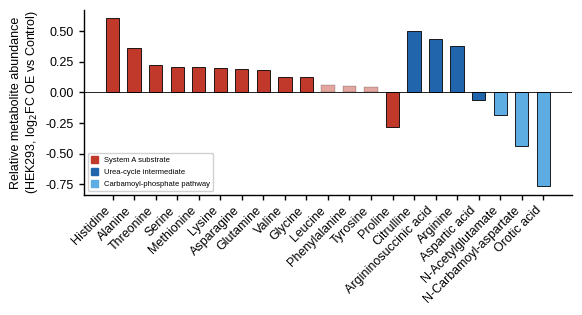

Saved: Fig3G_metabolomics.pdf


In [4]:
x = np.arange(len(t))
fig, ax = plt.subplots(figsize=(6.6, 2.4))
for xi, row in t.iterrows():
    sig = row['padj'] < 0.05
    ax.bar(xi, row['log2fc'], width=0.62, color=gcol[row['group']], edgecolor='black',
           linewidth=0.6 if sig else 0.3, alpha=1.0 if sig else 0.45)

ax.axhline(0, color='black', linewidth=0.6)
ax.set_xticks(x); ax.set_xticklabels(t['metabolite'], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Relative metabolite abundance\n(HEK293, log$_2$FC OE vs Control)', fontsize=9)
ax.tick_params(axis='y', labelsize=9)
for s in ['top', 'right']: ax.spines[s].set_visible(False)

legend_elements = [Patch(color=c, label=g) for g, c in gcol.items()]
ax.legend(handles=legend_elements, fontsize=5.5, loc='lower left', frameon=True,
          framealpha=0.9, handlelength=1.0, handleheight=1.0)

fig.subplots_adjust(left=0.16)
fig.savefig('Fig3G_metabolomics.pdf', bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved: Fig3G_metabolomics.pdf')

## Fig S9A — volcano plot (all 186 metabolites)

Companion panel to Fig. 3G. Same targeted metabolomics dataset, shown here as a full volcano plot
rather than the compact substrate/urea-cycle bar chart. Supports the results-text claim that 69/186
metabolites were significantly altered (FDR < 0.05; 24 increased, 45 decreased).

Colour-coded by the same categories as Fig. 3G (System A substrate, urea-cycle intermediate,
carbamoyl-phosphate pathway), plus oxidative stress and "other significant" -- the oxidative-stress
and "other significant" metabolites are discussed in the Supplementary Results text, so it's fine for
this supplementary figure to surface them too. Only significant (FDR<0.05) metabolites carry a text
label; non-significant points (including leucine and isoleucine) are shown as unlabelled grey dots.

**Data**: `ReSOLUTE_metabolomics_SLC48A4OE.xlsx` (raw, as exported from the ReSOLUTE dashboard).

In [5]:
raw = pd.read_excel('ReSOLUTE_metabolomics_SLC48A4OE.xlsx', engine='openpyxl')
df = raw.rename(columns={'adjusted p-value': 'padj', 'log2 fold-change': 'log2fc'})
df['padj']   = pd.to_numeric(df['padj'],   errors='coerce')
df['log2fc'] = pd.to_numeric(df['log2fc'], errors='coerce')
df['significant'] = df['padj'] < 0.05

# Same category membership as Fig 3G -- System A substrate is the non-redundant union of SNAT1/SNAT2/
# SNAT4 substrates (IUPHAR/BPS), not SLC38A4-specific alone; see Fig 3G markdown for rationale.
system_a  = ["Glutamine", "Alanine", "Serine", "Asparagine", "Threonine", "Glycine", "Methionine",
             "Histidine", "Valine", "Leucine", "Proline", "Tyrosine", "Phenylalanine", "Lysine"]
urea_core = ["Citrulline", "Arginine", "Argininosuccinic acid", "Aspartic Acid"]
carbamoyl = ["N-Acetylglutamic acid", "N-Carbamoyl-aspartic acid", "Orotic acid"]
oxidative = ["Glutathione oxidized", "Cystathionine", "Taurine"]

label_metabolites = system_a + urea_core + carbamoyl + oxidative

C_SYSA, C_UREA, C_CARB, C_OXID, C_OTHER, C_NS = '#C0392B', '#2166AC', '#5DADE2', '#8e44ad', '#f39c12', '#d9d9d9'

def grp(c):
    if c in system_a:  return 'System A substrate'
    if c in urea_core: return 'Urea-cycle intermediate'
    if c in carbamoyl: return 'Carbamoyl-phosphate pathway'
    if c in oxidative: return 'Oxidative stress'
    return 'Other'

def get_color(row):
    if not row['significant']:
        return C_NS
    return {'System A substrate': C_SYSA, 'Urea-cycle intermediate': C_UREA,
            'Carbamoyl-phosphate pathway': C_CARB, 'Oxidative stress': C_OXID,
            'Other': C_OTHER}[grp(row['compound'])]

df['group'] = df['compound'].apply(grp)
df.sort_values(['group', 'padj']).to_csv('Fig_S9A_metabolomics_volcano_data.csv', index=False)

n_sig = int(df['significant'].sum()); n_up = int((df['significant'] & (df['log2fc']>0)).sum())
n_dn  = int((df['significant'] & (df['log2fc']<0)).sum())
print(f"Total metabolites tested: {len(df)}  |  significant (FDR<0.05): {n_sig}  (up={n_up}, down={n_dn})")

Total metabolites tested: 186  |  significant (FDR<0.05): 69  (up=24, down=45)


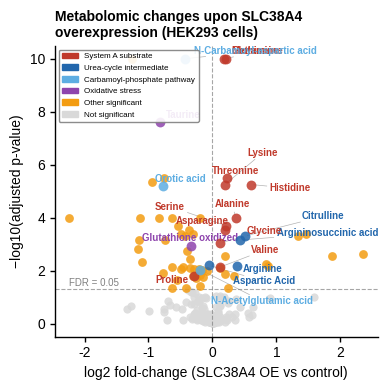

Saved: Fig_S9A_metabolomics_volcano.pdf


In [6]:
fig, ax = plt.subplots(figsize=(4, 4))

priority = {'System A substrate':4, 'Urea-cycle intermediate':4, 'Carbamoyl-phosphate pathway':4,
            'Oxidative stress':4, 'Other':3}
df['zorder'] = df.apply(lambda r: priority[r['group']] if r['significant'] else 2, axis=1)
df['size']   = df.apply(lambda r: 50 if (r['significant'] and r['group']!='Other') else (40 if r['significant'] else 35), axis=1)

for _, row in df.sort_values('zorder').iterrows():
    ax.scatter(row['log2fc'], -np.log10(max(row['padj'], 1e-10)), c=get_color(row),
               alpha=0.85, s=row['size'], linewidths=0, zorder=row['zorder'])

ax.axhline(-np.log10(0.05), linestyle='--', color='grey', linewidth=0.8, alpha=0.7)
ax.axvline(0, linestyle='--', color='grey', linewidth=0.8, alpha=0.7)
ax.text(df['log2fc'].min(), -np.log10(0.05) + 0.05, 'FDR = 0.05', fontsize=7, color='grey', va='bottom')

# only significant metabolites get a text label -- no forced labelling of non-significant points
labelled = df[df['compound'].isin(label_metabolites) & df['significant']]
texts = []
for _, row in labelled.iterrows():
    texts.append(ax.text(row['log2fc'], -np.log10(max(row['padj'], 1e-10)), row['compound'],
                          fontsize=7, color=get_color(row),
                          fontweight='bold' if row['group'] != 'Other' else 'normal'))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5, alpha=0.6), expand=(1.25, 1.5))

legend_elements = [
    mpatches.Patch(color=C_SYSA, label='System A substrate'),
    mpatches.Patch(color=C_UREA, label='Urea-cycle intermediate'),
    mpatches.Patch(color=C_CARB, label='Carbamoyl-phosphate pathway'),
    mpatches.Patch(color=C_OXID, label='Oxidative stress'),
    mpatches.Patch(color=C_OTHER, label='Other significant'),
    mpatches.Patch(color=C_NS, label='Not significant'),
]
ax.legend(handles=legend_elements, fontsize=5.8, loc='upper left', frameon=True, framealpha=0.9, edgecolor='grey')

ax.set_xlabel('log2 fold-change (SLC38A4 OE vs control)', fontsize=10)
ax.set_ylabel('−log10(adjusted p-value)', fontsize=10)
ax.set_title('Metabolomic changes upon SLC38A4\noverexpression (HEK293 cells)', fontsize=10, fontweight='bold', loc='left')
sns.despine(ax=ax)
plt.tight_layout()

fig.savefig('Fig_S9A_metabolomics_volcano.pdf', bbox_inches='tight')
plt.show()
print('Saved: Fig_S9A_metabolomics_volcano.pdf')

## MetaboAnalyst input list — compound annotation and identifier assignment

Generates the metabolite list submitted to MetaboAnalyst to produce the enrichment results plotted
below, so that the input to Fig. S9B is reproducible from the deposited data rather than assembled by
hand.

**Why this is needed.** The list submitted for the original analysis was a hybrid of compound labels:
of the 69 significant metabolites, 26 names came from the export's `compound` column, 8 from the
systematic name embedded in its `ChEBI` column, 34 were identical in both, and 1 was corrected
manually (`Fructose 1,6-biphosphate` is a spelling error in the source, for *bis*phosphate). That list
cannot be regenerated from the source file. Submitting identifiers instead removes the ambiguity: the
ReSOLUTE export carries a ChEBI identifier for every compound, and the HMDB identifiers below were
verified in the archived mapping (`provenance_metabolomics/`), so no name matching is involved.

**Three compounds need the generic entity name.** Their ChEBI names specify a tautomer, charge state or
regiochemistry that pathway libraries do not index separately: `keto-D-fructose 1,6-bisphosphate`
(fructose 1,6-bisphosphate), `(N(omega)-L-arginino)succinic acid` (argininosuccinic acid) and
`thiamine(1+)` (thiamine).

**Two are excluded.** `hexose 6-phosphate` and `hexose 1-phosphate` are chemical class terms, not
molecular entities — the mass spectrometry cannot separate glucose, fructose and mannose phosphates,
which share a formula and mass. No identifier can represent them, and no isomer is assigned: glucose
6-phosphate belongs to glycolysis, the pentose phosphate pathway, gluconeogenesis and amino sugar
metabolism, all of which appear among the enriched pathways, so assigning it on assumption would
inflate exactly those results. Both were also unmapped in the original analysis, so the enrichment
tests the same 67 metabolites either way. Their fold-changes remain in Table S7.

**Background.** Enrichment uses MetaboAnalyst's default library-wide background rather than the
measured panel. A measured-metabolome background was attempted but only ~126 of 186 compounds could be
mapped to HMDB identifiers, and the unmappable fraction is not random — it is concentrated in the
derivatised and non-canonical compounds — so it would not have represented the measured panel either.
The library background is stated in the Methods and the enrichment is reported as a relative ranking
of pathways.

In [7]:
import re

# ---- ChEBI identifiers, parsed from the free-text field: "glutamine (CHEBI:28300)" ----------------
CHEBI_PATTERN = re.compile(r'^(?P<name>.*?)\s*\(CHEBI:(?P<id>\d+)\)\s*$')
_p = df['ChEBI'].astype(str).str.strip().str.extract(CHEBI_PATTERN)
df['chebi_name']  = _p['name'].str.strip()
df['chebi_id']    = pd.to_numeric(_p['id'], errors='coerce').astype('Int64')
df['chebi_curie'] = 'CHEBI:' + df['chebi_id'].astype(str)
assert df['chebi_id'].notna().all() and df['chebi_id'].is_unique, 'ChEBI parsing incomplete or non-unique'

# ---- Compounds whose ChEBI name is too specific for a pathway library to index -------------------
GENERIC_ENTITY_NAME = {
    'CHEBI:16905': 'Fructose 1,6-bisphosphate',   # keto-D-fructose 1,6-bisphosphate
    'CHEBI:15682': 'Argininosuccinic acid',       # (N(omega)-L-arginino)succinic acid
    'CHEBI:18385': 'Thiamine',                    # thiamine(1+)
}
# ---- Chemical class terms: no molecular entity to map to, excluded from the submission ------------
CLASS_TERMS = {
    'CHEBI:47877': 'hexose 6-phosphate - isomers indistinguishable by mass',
    'CHEBI:24588': 'hexose 1-phosphate - isomers indistinguishable by mass',
}
df['excluded_from_enrichment'] = df['chebi_curie'].isin(CLASS_TERMS)

# ---- Verified HMDB identifiers from the archived mapping ------------------------------------------
name_map = pd.read_csv('provenance_metabolomics/MetaboAnalyst_2026-07_name_map.csv')
_ok = name_map.dropna(subset=['Match']).copy()
_ok['key'] = _ok['Query'].str.lower()
_lut = _ok.set_index('key')

def _norm(s):
    return re.sub(r'[^a-z0-9]', '', str(s).lower())

def resolve_hmdb(row):
    """Look the compound up by the name that pathway libraries index."""
    for candidate in (GENERIC_ENTITY_NAME.get(row['chebi_curie']), row['compound'], row['chebi_name']):
        if candidate is None:
            continue
        key = str(candidate).lower()
        if key in _lut.index:
            hit = _lut.loc[key]
            if isinstance(hit, pd.DataFrame):
                hit = hit.iloc[0]
            return pd.Series({'submitted_name': candidate, 'hmdb_id': hit['HMDB'],
                              'kegg_id': hit['KEGG'] if pd.notna(hit['KEGG']) else None})
    return pd.Series({'submitted_name': None, 'hmdb_id': None, 'kegg_id': None})

df[['submitted_name', 'hmdb_id', 'kegg_id']] = df.apply(resolve_hmdb, axis=1)

# ---- Write the submission list --------------------------------------------------------------------
enrich   = df['significant'] & ~df['excluded_from_enrichment']
hmdb_ids = df.loc[enrich & df['hmdb_id'].notna(), 'hmdb_id'].tolist()

with open('MetaboAnalyst_input_significant_HMDB.txt', 'w') as fh:
    fh.write('\n'.join(hmdb_ids) + '\n')

prov = df.loc[df['significant'],
              ['compound', 'chebi_name', 'chebi_curie', 'submitted_name', 'hmdb_id', 'kegg_id',
               'log2fc', 'padj', 'excluded_from_enrichment']].copy()
prov['note'] = prov['chebi_curie'].map(CLASS_TERMS).fillna(
    prov['chebi_curie'].map({k: 'generic entity name used' for k in GENERIC_ENTITY_NAME})).fillna('')
prov = prov.sort_values('padj')
prov.to_csv('MetaboAnalyst_input_provenance.csv', index=False)

print(f'significant metabolites            : {int(df.significant.sum())}')
print(f'  excluded as chemical class terms : {int((df.significant & df.excluded_from_enrichment).sum())}')
print(f'  submitted to MetaboAnalyst       : {len(hmdb_ids)}  (all with a verified HMDB identifier)')
print(f'\nMetaboAnalyst_input_significant_HMDB.txt  {len(hmdb_ids)} identifiers')
print(f'MetaboAnalyst_input_provenance.csv        {len(prov)} rows')

assert df.loc[enrich, 'hmdb_id'].notna().all(), 'a submitted metabolite lacks an HMDB identifier'
assert len(hmdb_ids) == len(set(hmdb_ids)), 'duplicate HMDB identifiers in the submission list'

display(prov.loc[prov.note != '', ['compound','chebi_name','submitted_name','hmdb_id','note']])

significant metabolites            : 69
  excluded as chemical class terms : 2
  submitted to MetaboAnalyst       : 67  (all with a verified HMDB identifier)

MetaboAnalyst_input_significant_HMDB.txt  67 identifiers
MetaboAnalyst_input_provenance.csv        69 rows


,compound,chebi_name,submitted_name,hmdb_id,note
14,"Fructose 1,6-biphosphate","keto-D-fructose 1,6-bisphosphate","Fructose 1,6-bisphosphate",HMDB0001058,generic entity name used
28,Argininosuccinic acid,(N(omega)-L-arginino)succinic acid,Argininosuccinic acid,HMDB0000052,generic entity name used
36,Thiamine,thiamine(1+),Thiamine,HMDB0000235,generic entity name used
45,Hexose 6-phosphate,hexose 6-phosphate,None,None,hexose 6-phosphate - isomers indistinguishable...
52,Hexose 1-phosphate,hexose 1-phosphate,None,None,hexose 1-phosphate - isomers indistinguishable...


## Table S7 — full ReSOLUTE targeted metabolomics results

All 186 detected metabolites, not only the significant ones, with the compound identifiers assigned
above so that every row is traceable to a database entry rather than to a display label.

Columns: the ReSOLUTE display label and the ChEBI systematic name are both given, since they often
differ and the label is the less precise of the two; ChEBI identifiers are parsed from the export and
present for every compound; HMDB and KEGG identifiers are populated for the significant subset, which
is the part covered by the archived MetaboAnalyst mapping. `used in enrichment (Fig. S9B)` records
which metabolites were submitted for enrichment and marks the two chemical class terms that could not
be, so the table and Fig. S9B can be reconciled directly.

Two points a reader may query. An adjusted p-value of exactly 0 is what the ReSOLUTE dashboard
reports for the most significant compounds; it is reproduced unaltered rather than substituted with a
bound. `score across analyses` is a dashboard metric scoring how unusual each metabolite's regulation
is for SLC38A4 relative to the wider ReSOLUTE compendium — it is not a within-analysis significance
measure, and the adjusted p-value should be used for that.

In [8]:
# ---- Table S7 -- full ReSOLUTE targeted metabolomics results (all 186 metabolites) ----
# Formatted to match the other Tables: bold title in row 1, blank row 2, headers in
# row 3, data from row 4, frozen header. Identifier columns come from the annotation section above.
from openpyxl.styles import Font, Alignment
from openpyxl.utils import get_column_letter

ST7_TITLE = ('Table S7. HEK293-SLC38A4 overexpression targeted metabolomics results '
             '(ReSOLUTE consortium)')

st7 = df[['compound', 'chebi_name', 'chebi_curie', 'hmdb_id', 'kegg_id', 'formula',
          'monoisotopic mass', 'log2fc', 'padj', 'score across analyses',
          'significant', 'group', 'excluded_from_enrichment']].copy()
st7 = st7.rename(columns={
    'compound'                 : 'compound (ReSOLUTE label)',
    'chebi_name'               : 'systematic name (ChEBI)',
    'chebi_curie'              : 'ChEBI ID',
    'hmdb_id'                  : 'HMDB ID',
    'kegg_id'                  : 'KEGG ID',
    'monoisotopic mass'        : 'monoisotopic mass',
    'log2fc'                   : 'log2FC (OE vs control)',
    'padj'                     : 'adjusted p-value',
    'score across analyses'    : 'score across analyses (cross-analysis specificity)',
    'group'                    : 'biological group',
})
st7['direction'] = np.where(st7['significant'],
                            np.where(st7['log2FC (OE vs control)'] > 0, 'Up', 'Down'), '')
st7['used in enrichment (Fig. S9B)'] = np.where(
    st7['significant'] & ~st7['excluded_from_enrichment'], 'Yes',
    np.where(st7['significant'], 'No - chemical class term', ''))
st7 = st7.drop(columns=['excluded_from_enrichment'])
st7 = st7.sort_values(['significant', 'adjusted p-value'],
                      ascending=[False, True]).reset_index(drop=True)

n_sig = int(st7['significant'].sum())
n_up  = int((st7['significant'] & (st7['direction'] == 'Up')).sum())
n_dn  = int((st7['significant'] & (st7['direction'] == 'Down')).sum())
n_enr = int((st7['used in enrichment (Fig. S9B)'] == 'Yes').sum())

ST7_PATH = 'Table_S7_SLC38A4_OE_metabolomics.xlsx'
with pd.ExcelWriter(ST7_PATH, engine='openpyxl') as xw:
    st7.to_excel(xw, sheet_name='Table S7', index=False, startrow=2)
    ws = xw.sheets['Table S7']
    ws['A1'] = ST7_TITLE
    ws['A1'].font = Font(bold=True, size=12)
    for cell in ws[3]:
        cell.font = Font(bold=True)
        cell.alignment = Alignment(wrap_text=True, vertical='bottom')
    ws.freeze_panes = 'A4'
    widths = [26, 34, 14, 14, 10, 12, 18, 20, 16, 44, 11, 28, 10, 28]
    for i, w in enumerate(widths[:st7.shape[1]], start=1):
        ws.column_dimensions[get_column_letter(i)].width = w

print(f'{ST7_PATH}: {len(st7)} metabolites; {n_sig} significant ({n_up} up, {n_dn} down); '
      f'{n_enr} submitted for enrichment.')
print(f'  identifier coverage: ChEBI {int(st7["ChEBI ID"].notna().sum())}/{len(st7)}, '
      f'HMDB {int(st7["HMDB ID"].notna().sum())}/{len(st7)}, '
      f'KEGG {int(st7["KEGG ID"].notna().sum())}/{len(st7)}')
print('  (HMDB/KEGG are populated for the significant subset, which is what the archived mapping covers.)')
st7.head(4)

Table_S7_SLC38A4_OE_metabolomics.xlsx: 186 metabolites; 69 significant (24 up, 45 down); 67 submitted for enrichment.
  identifier coverage: ChEBI 186/186, HMDB 67/186, KEGG 65/186
  (HMDB/KEGG are populated for the significant subset, which is what the archived mapping covers.)


,compound (ReSOLUTE label),systematic name (ChEBI),ChEBI ID,HMDB ID,KEGG ID,formula,monoisotopic mass,log2FC (OE vs control),adjusted p-value,score across analyses (cross-analysis specificity),significant,biological group,direction,used in enrichment (Fig. S9B)
0,Glutamine,glutamine,CHEBI:28300,HMDB0000641,C00064,C5H10N2O3,146.0691,0.1793,0.0,1.1724,True,System A substrate,Up,Yes
1,Methionine,methionine,CHEBI:16811,HMDB0000696,C00073,C5H11NO2S,149.0511,0.2065,0.0,1.8945,True,System A substrate,Up,Yes
2,N-Carbamoyl-aspartic acid,N-carbamoylaspartic acid,CHEBI:64850,HMDB0000828,C00438,C5H8N2O5,176.0433,-0.4360,0.0,-1.5358,True,Carbamoyl-phosphate pathway,Down,Yes
3,Ribose 5-phosphate,D-ribofuranose 5-phosphate,CHEBI:52742,HMDB0001548,C00117,C5H11O8P,230.0191,-1.2613,0.0,-5.4682,True,Other,Down,Yes


## Fig S9B — pathway enrichment (MetaboAnalyst)

Companion panel to Fig. 3G/S9A. MetaboAnalyst over-representation analysis of the metabolites
significantly altered by SLC38A4 overexpression (FDR < 0.05). Supports the results-text claim that
aspartate metabolism, arginine and proline metabolism, and the urea cycle are among the top enriched
pathways. All 16 significant pathways are colour-coded by biological theme (amino acid metabolism /
nitrogen-urea cycle / energy-nucleotide metabolism), not just the three named in the main text — the
rest are discussed in the Supplementary Results, so it's fine to highlight them here too.

**Data**: `MetaboAnalyst_pathway_enrichment_results.csv` (81 pathways tested; MetaboAnalyst output).


In [9]:
enr = pd.read_csv('MetaboAnalyst_pathway_enrichment_results.csv')
enr = enr.rename(columns={'Raw p': 'raw_p', 'Holm p': 'holm_p', 'FDR': 'fdr'})
enr['hit_ratio'] = enr['hits'] / enr['total']

sig_enrichment = enr[enr['fdr'] < 0.05].copy().sort_values('fdr', ascending=True).reset_index(drop=True)
sig_enrichment.to_csv('Fig_S9B_pathway_enrichment_data.csv', index=False)

print(f"Enrichment results loaded: {len(enr)} pathways total")
print(f"Significantly enriched (FDR < 0.05): {len(sig_enrichment)}")
display(sig_enrichment[['pathway','hits','total','hit_ratio','raw_p','fdr']].round({'hit_ratio':3,'raw_p':6,'fdr':6}))


Enrichment results loaded: 81 pathways total
Significantly enriched (FDR < 0.05): 16


,pathway,hits,total,hit_ratio,raw_p,fdr
0,Aspartate Metabolism,12,35,0.343,0.000000,0.000007
1,Arginine and Proline Metabolism,13,52,0.250,0.000001,0.000060
2,Urea Cycle,9,28,0.321,0.000007,0.000235
3,Ammonia Recycling,9,31,0.290,0.000018,0.000391
4,Pyrimidine Metabolism,12,57,0.211,0.000024,0.000391
5,Warburg Effect,12,57,0.211,0.000024,0.000391
6,Purine Metabolism,13,73,0.178,0.000070,0.000976
7,Glutamate Metabolism,10,48,0.208,0.000141,0.001730
8,Amino Sugar Metabolism,8,33,0.242,0.000235,0.002400
9,Phosphatidylethanolamine Biosynthesis,5,12,0.417,0.000245,0.002400


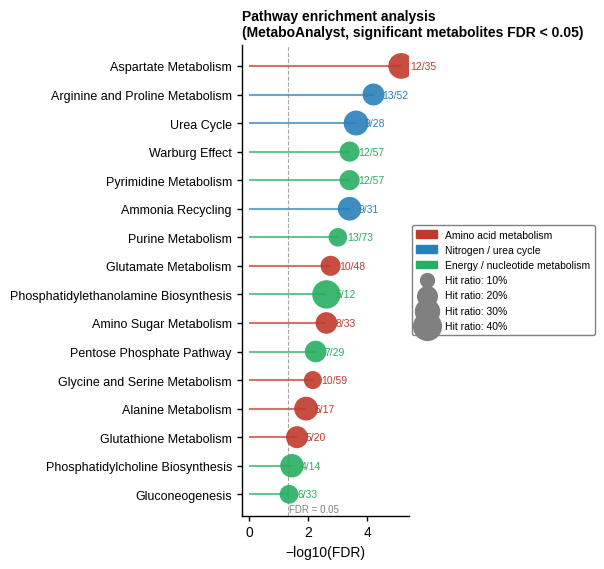

Saved: Fig_S9B_pathway_enrichment.pdf


In [10]:
def get_pathway_color(pathway):
    amino_acid_pathways = ["Aspartate", "Glutamate", "Glycine", "Serine", "Alanine",
                            "Amino Sugar", "Glutathione"]
    nitrogen_pathways   = ["Urea", "Ammonia", "Arginine", "Proline"]
    energy_pathways     = ["Warburg", "Purine", "Pyrimidine", "Pentose",
                            "Gluconeogenesis", "Phosphatidyl"]
    if any(kw in pathway for kw in amino_acid_pathways): return '#c0392b'   # amino acid metabolism
    if any(kw in pathway for kw in nitrogen_pathways):   return '#2980b9'  # nitrogen / urea cycle
    if any(kw in pathway for kw in energy_pathways):     return '#27ae60'  # energy / nucleotide
    return '#f39c12'                                                       # other

sig_enrichment['color'] = sig_enrichment['pathway'].apply(get_pathway_color)

fig, ax = plt.subplots(figsize=(7.6, len(sig_enrichment) * 0.3 + 1))
plot_df = sig_enrichment.sort_values('fdr', ascending=False)   # most significant at top
y_pos = range(len(plot_df))

ax.hlines(y=list(y_pos), xmin=0, xmax=-np.log10(plot_df['fdr']), colors=plot_df['color'],
          linewidth=1.5, alpha=0.7)
ax.scatter(-np.log10(plot_df['fdr']), list(y_pos), c=plot_df['color'],
           s=plot_df['hit_ratio'] * 1000, zorder=3, alpha=0.9, linewidths=0)

ax.axvline(-np.log10(0.05), linestyle='--', color='grey', linewidth=0.8, alpha=0.7)
ax.text(-np.log10(0.05) + 0.05, -0.7, 'FDR = 0.05', fontsize=7, color='grey', va='bottom')

ax.set_yticks(list(y_pos)); ax.set_yticklabels(plot_df['pathway'], fontsize=9)
for i, (_, row) in enumerate(plot_df.iterrows()):
    ax.text(-np.log10(row['fdr']) + 0.3, i, f"{int(row['hits'])}/{int(row['total'])}",
            va='center', ha='left', fontsize=7.5, color=row['color'])

ax.set_xlabel('−log10(FDR)', fontsize=10)
ax.set_title('Pathway enrichment analysis\n(MetaboAnalyst, significant metabolites FDR < 0.05)',
             fontsize=10, fontweight='bold', loc='left')

theme_legend = [
    mpatches.Patch(color='#c0392b', label='Amino acid metabolism'),
    mpatches.Patch(color='#2980b9', label='Nitrogen / urea cycle'),
    mpatches.Patch(color='#27ae60', label='Energy / nucleotide metabolism'),
]
size_legend = [plt.scatter([], [], c='grey', s=s * 1000, alpha=1, label=f'Hit ratio: {l}')
               for s, l in [(0.1, '10%'), (0.2, '20%'), (0.3, '30%'), (0.4, '40%')]]
ax.legend(handles=theme_legend + size_legend, fontsize=7.5,
          loc='center left', bbox_to_anchor=(1.02, 0.5),
          frameon=True, framealpha=1, edgecolor='grey', borderaxespad=0)

sns.despine(ax=ax)
plt.tight_layout(rect=[0, 0, 0.82, 1])
fig.savefig('Fig_S9B_pathway_enrichment.pdf', bbox_inches='tight')
plt.show()
print('Saved: Fig_S9B_pathway_enrichment.pdf')


## Table S8 — full MetaboAnalyst pathway enrichment results (all 81 pathways)

Fig. S9B shows only the 16 pathways significant at FDR<0.05. This table reports the full MetaboAnalyst over-representation output (81 pathways tested against the human metabolome database library), so reviewers can see the complete ranking rather than only the pre-filtered significant subset.

In [11]:
# ---- Table S8 -- full MetaboAnalyst pathway enrichment results ----
st8 = enr.copy().sort_values("fdr", ascending=True).reset_index(drop=True)
st8["significant_FDR<0.05"] = st8["fdr"] < 0.05
st8 = st8[["pathway", "total", "expected", "hits", "hit_ratio", "raw_p", "holm_p", "fdr",
             "significant_FDR<0.05"]]

n_total_pathways = int(len(st8))
n_sig = int(st8["significant_FDR<0.05"].sum())
assert n_sig == 16, f"expected 16 significant pathways per SI Results, got {n_sig}"

ST8_PATH = "Table_S8_metabolite_pathway_enrichment.xlsx"
_readme_s8 = pd.DataFrame({"Table S8 - Full MetaboAnalyst pathway enrichment "
                            "results for the significantly altered ReSOLUTE metabolites": [
    "Pathway (over-representation) enrichment analysis of the metabolites significantly "
    "altered by SLC38A4 overexpression (FDR<0.05 in Table S7; 69 metabolites), performed with "
    "MetaboAnalyst v6.0 (Pang et al., Nucleic Acids Res 2024, doi:10.1093/nar/gkae253) using "
    "the human metabolome database (HMDB) pathway library (Supplementary Methods 3.3).",
    f"{n_sig} of {n_total_pathways} pathways tested are significant at FDR<0.05 -- matches the "
    "Supplementary Results (\"Pathway enrichment analysis...identified 16 significantly "
    "enriched pathways\") and Fig. S9B, which plots only these 16. This table reports all "
    f"{n_total_pathways} pathways tested, not only the significant subset, so the full ranking "
    "is available alongside the figure.",
    "Of the 69 significant metabolites, 67 were mapped to an HMDB/KEGG identifier and submitted "
    "to MetaboAnalyst; 2 (both named as ambiguous chemical-class terms rather than a single "
    "compound: \"Hexose 6-phosphate\" and \"Hexose 1-phosphate\") were excluded because their "
    "isomers cannot be distinguished by mass. The full per-metabolite input list, identifiers, "
    "and which metabolites were used in this enrichment are in Table S7 (column \"used in "
    "enrichment (Fig. S9B)\") -- not duplicated here.",
    "Columns: pathway (MetaboAnalyst/HMDB pathway name); total (number of compounds in the "
    "pathway library); expected (expected hits by chance, hypergeometric test); hits (observed "
    "hits from the 67 submitted metabolites); hit_ratio (hits/total); raw_p (hypergeometric "
    "test p-value); holm_p (Holm-Bonferroni-adjusted p-value); fdr (Benjamini-Hochberg FDR); "
    "significant_FDR<0.05 (whether this pathway meets the threshold used in the manuscript, "
    "and is therefore one of the 16 pathways plotted in Fig. S9B).",
    "Source data: MetaboAnalyst_pathway_enrichment_results.csv, generated by MetaboAnalyst "
    "v6.0 (external web tool; not re-run in this notebook) and loaded as-is by "
    "Fig3G_S9AB_metabolomics.ipynb.",
]})
with pd.ExcelWriter(ST8_PATH, engine="openpyxl") as xw:
    _readme_s8.to_excel(xw, sheet_name="README", index=False)
    st8.to_excel(xw, sheet_name="Pathway_enrichment", index=False)

print(f"{n_sig} of {n_total_pathways} pathways significant at FDR<0.05. Saved: {ST8_PATH}")
st8.head(5)


16 of 81 pathways significant at FDR<0.05. Saved: Table_S8_metabolite_pathway_enrichment.xlsx


,pathway,total,expected,hits,hit_ratio,raw_p,holm_p,fdr,significant_FDR<0.05
0,Aspartate Metabolism,35,1.92,12,0.342857,7.090000e-08,0.000007,0.000007,True
1,Arginine and Proline Metabolism,52,2.85,13,0.250000,1.230000e-06,0.000119,0.000060,True
2,Urea Cycle,28,1.54,9,0.321429,7.200000e-06,0.000691,0.000235,True
3,Ammonia Recycling,31,1.70,9,0.290323,1.850000e-05,0.001760,0.000391,True
4,Pyrimidine Metabolism,57,3.13,12,0.210526,2.390000e-05,0.002250,0.000391,True


## Fig S9C — KO transcripts vs OE metabolites: loss-/gain-of-function mirror

Closing panel for the metabolomics story, in two parts. (A) Mean SLC38A4-knockout transcript log2FC
(loss of function) beside mean SLC38A4-overexpression metabolite log2FC (gain of function), for the
two axes shared between the datasets. (B) The individual gene- and metabolite-level values underlying
each mean in (A), shown as box plots (median/IQR, no fliers) with every data point overlaid -- included
because these are small groups (3 amino-acid-transport genes, 4 urea-cycle metabolites), so the mean
alone would understate how much a single gene or metabolite drives the result.

The urea-cycle metabolite axis deliberately uses only the 4 core urea-cycle intermediates (citrulline,
argininosuccinic acid, arginine, aspartic acid), NOT the carbamoyl-phosphate pathway markers
(N-acetylglutamate, N-carbamoyl-aspartate, orotic acid) that are shown separately in Fig. 3G/S9A. Those
three markers decrease on overexpression (same direction as the KO transcripts), while the four core
intermediates increase (the opposite, "mirror" signal) -- averaging them together would cancel out the
very effect this panel demonstrates, even though both signatures independently support enhanced
urea-cycle flux. Gene modules are restricted to the same transport system as the metabolite groups
defined in Fig. 3G (System A/N genes only, not the non-hepatic System L/xc- transporters shown
separately in Fig. 3J). The amino-acid-transport module uses the System A and System N SLC38 members
(classification as in Fig. 3H) that are both detected here and concordant between the two independent
KO clones: SLC38A2, SLC38A1 and SLC38A3. Two are excluded. SLC38A4 is the deleted gene, so its own
downregulation reports knockout efficiency rather than a coordinated transport response and averaging
it in would be circular (including it gives -1.13). SLC38A6 is sign-discordant between clones (KO 1
-0.159, FDR 8.8e-3; KO 2 +0.069, ns) and so fails the same clone-concordance standard applied to the
developmental signatures in Fig. S8B (including it gives -0.57). SLC38A5 is not detected. The
urea-cycle gene list is kept identical to the curated panel in
`Fig3_KO_RNAseq_metabolism.ipynb`/Fig. 3E/S8A -- update both together if either list changes).

**Data**: `Fig3C_limma_KO_vs_WT_combined_mincount10.csv` (KO transcriptomics); `Fig3G_metabolomics_data.csv` (OE
metabolomics, already used for Fig. 3G above).

In [12]:
# ---- Load KO transcriptomics (new input, added for the mirror panel) --------
ko_de = (pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0)
           .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))

# Gene modules restricted to the SAME transport system as the metabolite axes below.
# Amino-acid-transport module: System A / System N SLC38 members (classification as in Fig. 3H,
# from UniProt reviewed entries) that are BOTH detected here AND concordant between the two
# independent KO clones. Two genes are deliberately excluded:
#   - SLC38A4: it is the deleted gene, so its own downregulation reports knockout efficiency
#     rather than a coordinated transport response; including it would be circular.
#   - SLC38A6: sign-discordant between clones (KO 1 -0.159, FDR 8.8e-3; KO 2 +0.069, ns), so it
#     fails the same clone-concordance standard applied to the developmental signatures in Fig. S8B.
# SLC38A5 is not detected in this dataset.
AA_TRANSPORT_GENES = ['SLC38A2', 'SLC38A1', 'SLC38A3']
UREA_CYCLE_GENES = ['CPS1', 'NAGS', 'OTC', 'ASS1', 'ASL', 'ARG1', 'ARG2', 'SLC25A15', 'SLC25A13',
                     'GLUL', 'GLS', 'GOT1', 'GOT2', 'GPT2', 'ASNS', 'ALDH4A1', 'CAD']

def mean_ko_lfc(genes):
    return ko_de.reindex([g for g in genes if g in ko_de.index])['logFC'].mean()

# Metabolite side: reuse Fig 3G's own curated groups directly, so both halves of this panel are
# guaranteed consistent with Fig 3G's categories (no re-deriving group membership here). Note the urea
# cycle axis is deliberately restricted to 'Urea-cycle intermediate' (4 members) and excludes
# 'Carbamoyl-phosphate pathway' -- see markdown above for why.
met = pd.read_csv('Fig3G_metabolomics_data.csv').dropna(subset=['log2fc'])

def mean_met_lfc(group):
    return met.loc[met.group == group, 'log2fc'].mean()

AXES = [
    ('Amino-acid pool /\ntransport', AA_TRANSPORT_GENES, 'System A substrate'),
    ('Urea cycle /\nnitrogen',       UREA_CYCLE_GENES,   'Urea-cycle intermediate'),
]
labels  = [a[0] for a in AXES]
ko_vals = [mean_ko_lfc(a[1]) for a in AXES]
oe_vals = [mean_met_lfc(a[2]) for a in AXES]

mirror = pd.DataFrame({'axis': labels, 'KO_mean_gene_log2FC': ko_vals, 'OE_mean_metabolite_log2FC': oe_vals})
mirror.round(3)

,axis,KO_mean_gene_log2FC,OE_mean_metabolite_log2FC
0,Amino-acid pool /\ntransport,-0.746,0.165
1,Urea cycle /\nnitrogen,-0.774,0.315


In [13]:
# ---- Group-mean summary (numeric record only) --------------------------------
# The mean-bar version of this panel is not used in the manuscript: Fig. S9C shows the
# individual-value boxplots produced in the next cells. The group means are still written out
# here because they are the values quoted in the Fig. S9C legend and Supplementary Results.
# (C_KO / C_OE are the shared panel colours, also used by the boxplot cell below.)
C_KO, C_OE = '#E08214', '#2ca25f'   # orange KO (matches Fig 3I/3J house style), green OE (matches the SNAT4-substrate green used in S9A)

mirror.to_csv('Fig_S9C_KO_OE_mirror_data.csv', index=False)
print('Saved: Fig_S9C_KO_OE_mirror_data.csv (group means; no figure generated)')
display(mirror.round(3))


Saved: Fig_S9C_KO_OE_mirror_data.csv (group means; no figure generated)


,axis,KO_mean_gene_log2FC,OE_mean_metabolite_log2FC
0,Amino-acid pool /\ntransport,-0.746,0.165
1,Urea cycle /\nnitrogen,-0.774,0.315


In [14]:
# ---- Panel B: individual values underlying each mean in Panel A -------------
long_rows = []
for g in AA_TRANSPORT_GENES:
    long_rows.append({'axis': 'Amino-acid pool /\ntransport', 'dataset': 'KO transcripts', 'val': ko_de.loc[g, 'logFC']})
for g in UREA_CYCLE_GENES:
    if g in ko_de.index:
        long_rows.append({'axis': 'Urea cycle /\nnitrogen', 'dataset': 'KO transcripts', 'val': ko_de.loc[g, 'logFC']})
for _, r in met[met.group == 'System A substrate'].iterrows():
    long_rows.append({'axis': 'Amino-acid pool /\ntransport', 'dataset': 'OE metabolites', 'val': r['log2fc']})
for _, r in met[met.group == 'Urea-cycle intermediate'].iterrows():
    long_rows.append({'axis': 'Urea cycle /\nnitrogen', 'dataset': 'OE metabolites', 'val': r['log2fc']})
mirror_long = pd.DataFrame(long_rows)
mirror_long.to_csv('Fig_S9C_KO_OE_mirror_individual_values.csv', index=False)
mirror_long.groupby(['axis', 'dataset']).size().rename('n')

axis                          dataset       
Amino-acid pool /\ntransport  KO transcripts     3
                              OE metabolites    14
Urea cycle /\nnitrogen        KO transcripts    17
                              OE metabolites     4
Name: n, dtype: int64

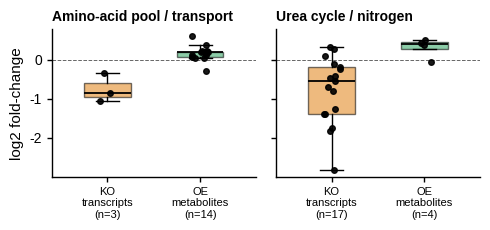

Saved: Fig_S9C_KO_OE_mirror_individual_values.[pdf] + .csv


In [15]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(5, 2.4), sharey=True)
for ax, axis_name in zip(axes, ['Amino-acid pool /\ntransport', 'Urea cycle /\nnitrogen']):
    sub = mirror_long[mirror_long.axis == axis_name]
    xticklabs = []
    for i, (ds, col) in enumerate([('KO transcripts', C_KO), ('OE metabolites', C_OE)]):
        vals = sub.loc[sub.dataset == ds, 'val'].values
        n = len(vals)
        xticklabs.append(f"{ds.split()[0]}\n{ds.split()[1]}\n(n={n})")
        ax.boxplot([vals], positions=[i], widths=0.5, patch_artist=True, showfliers=False,
                   medianprops=dict(color='black', lw=1.3), whiskerprops=dict(color='black', lw=1),
                   capprops=dict(color='black', lw=1),
                   boxprops=dict(facecolor=col, alpha=0.55, edgecolor='black', lw=1))
        jitter = rng.uniform(-0.09, 0.09, n)
        ax.scatter(np.full(n, i) + jitter, vals, color='black', s=16, zorder=3, alpha=0.9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(xticklabs, fontsize=8)
    ax.axhline(0, color='0.4', lw=0.7, ls='--')
    ax.set_title(axis_name.replace(chr(10), ' '), fontsize=10, fontweight='bold', loc='left')
    ax.set_ylabel('log2 fold-change' if ax is axes[0] else '', fontsize=AXTITLE)
    ax.set_xlim(-0.6, 1.6)
plt.tight_layout()
fig.savefig('Fig_S9C_KO_OE_mirror_individual_values.pdf', bbox_inches='tight')
plt.show()
print('Saved: Fig_S9C_KO_OE_mirror_individual_values.[pdf] + .csv')

*Note: will use only the box plots in Fig. S9 as they offer the same message as the bar plots, but with more granularity*